In [7]:
import os
import sys

os.chdir("/kaggle/working/Debiasing")

from data import load_adult

data = load_adult(verbose=True)

print("\nDataset loaded successfully!")
print("Number of features:", data["n_features"])
print("Training samples:", len(data["train_ds"]))
print("Test samples:", len(data["y_test"]))
print("Device:", data["device"])

Train: (31655, 102), Test: (13567, 102)
P(y=1) = 0.248   P(z=Male) = 0.675
P(y=1 | Male) = 0.312   P(y=1 | Female) = 0.114

Dataset loaded successfully!
Number of features: 102
Training samples: 31655
Test samples: 13567
Device: cuda


In [15]:
import os

os.chdir("/kaggle/working/Debiasing")

!python main.py

Train: (31655, 102), Test: (13567, 102)
P(y=1) = 0.248   P(z=Male) = 0.675
P(y=1 | Male) = 0.312   P(y=1 | Female) = 0.114
Using device: cuda

=== 1. Baseline (no debiasing) ===
Predictor using GPUs: [0, 1]
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return F.linear(input, self.weight, self.bias)
epoch   1 | L_P 0.3782 | L_A 0.0000 | acc 0.8449 | DP 0.160 | TPR 0.077 | FPR 0.063
epoch   5 | L_P 0.3079 | L_A 0.0000 | acc 0.8489 | DP 0.171 | TPR 0.073 | FPR 0.071
epoch  10 | L_P 0.2994 | L_A 0.0000 | acc 0.8488 | DP 0.173 | TPR 0.053 | FPR 0.075
epoch  15 | L_P 0.2934 | L_A 0.0000 | acc 0.8497 | DP 0.182 | TPR 0.071 | FPR 0.080
epoch  20 | L_P 0.2910 | L_A 0.0000 | acc 0.8492 | DP 0.180 | TPR 0.083 | FPR 0.078

=== 2. Debiased: demographic parity ===
Predictor us

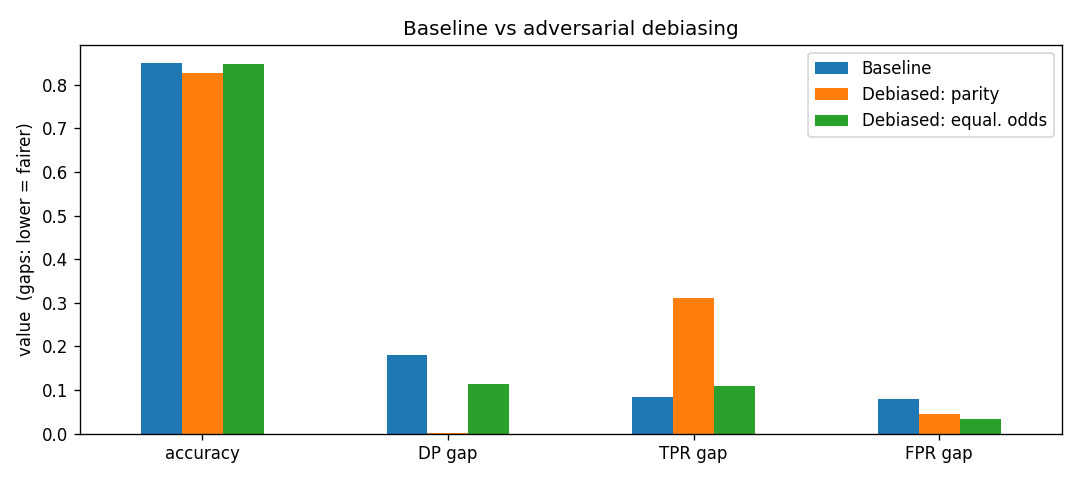

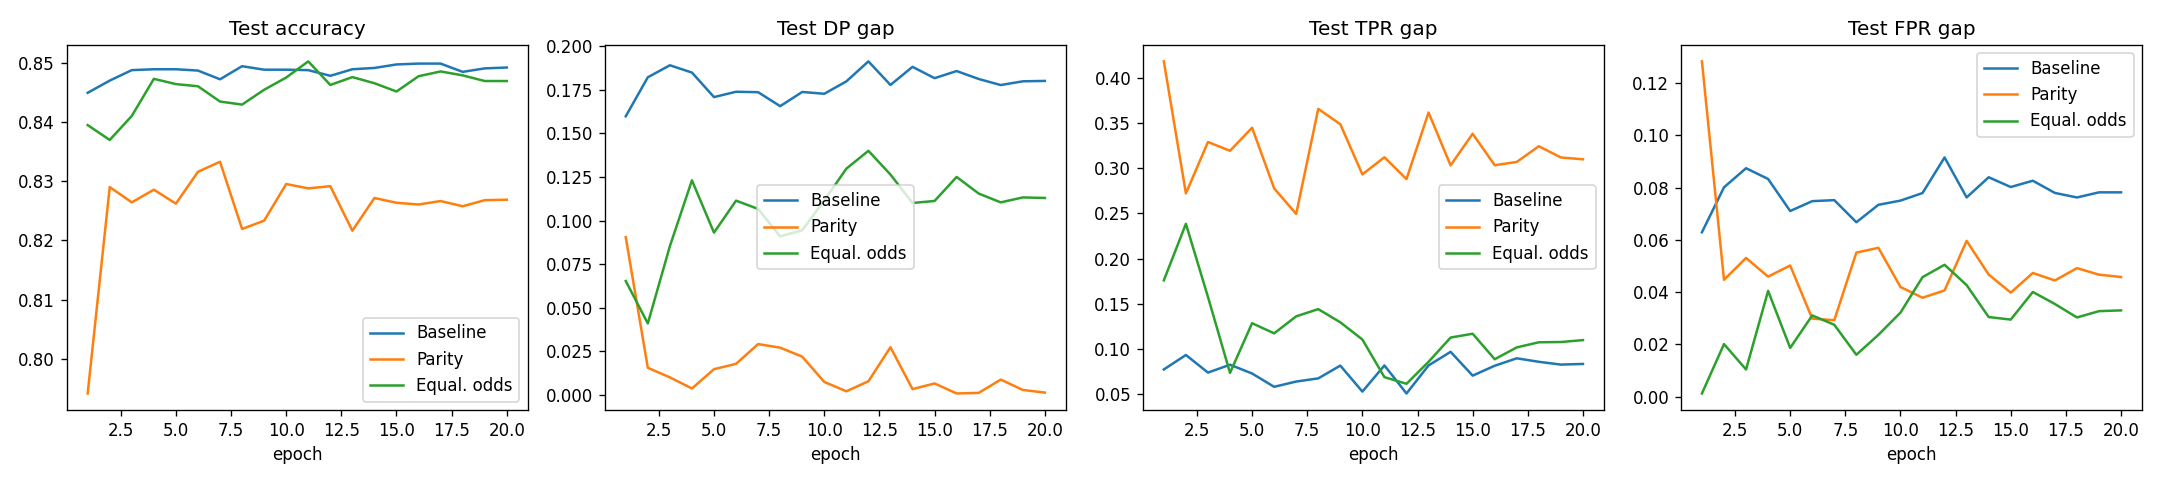

In [16]:
from IPython.display import Image, display

display(Image("comparison.png"))
display(Image("curves.png"))

In [17]:
import os
import torch
from train import train

os.chdir("/kaggle/working/Debiasing")

# Run 1: Baseline
print("Training Baseline...")
P_base, hist_base = train(
    data,
    debias=False,
    epochs=20
)

# Run 2: Demographic Parity
print("\nTraining Demographic Parity...")
P_dp, hist_dp = train(
    data,
    mode="parity",
    alpha=1.0,
    epochs=20
)

print("\nBoth models trained successfully!")

Training Baseline...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.3782 | L_A 0.0000 | acc 0.8449 | DP 0.160 | TPR 0.077 | FPR 0.063
epoch   5 | L_P 0.3079 | L_A 0.0000 | acc 0.8489 | DP 0.171 | TPR 0.073 | FPR 0.071
epoch  10 | L_P 0.2994 | L_A 0.0000 | acc 0.8488 | DP 0.173 | TPR 0.053 | FPR 0.075
epoch  15 | L_P 0.2934 | L_A 0.0000 | acc 0.8497 | DP 0.182 | TPR 0.071 | FPR 0.080
epoch  20 | L_P 0.2910 | L_A 0.0000 | acc 0.8492 | DP 0.180 | TPR 0.083 | FPR 0.078

Training Demographic Parity...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.4092 | L_A 0.6348 | acc 0.7941 | DP 0.090 | TPR 0.418 | FPR 0.128
epoch   5 | L_P 0.3640 | L_A 0.6301 | acc 0.8262 | DP 0.015 | TPR 0.345 | FPR 0.050
epoch  10 | L_P 0.3518 | L_A 0.6301 | acc 0.8295 | DP 0.007 | TPR 0.293 | FPR 0.042
epoch  15 | L_P 0.3466 | L_A 0.6300 | acc 0.8263 | DP 0.006 | TPR 0.338 | FPR 0.040
epoch  20 | L_P 0.3457 | L_A 0.6301 | acc 0.8269 | DP 0.001 | TPR 0.310 | FPR 0.046

Both models trained successfully!


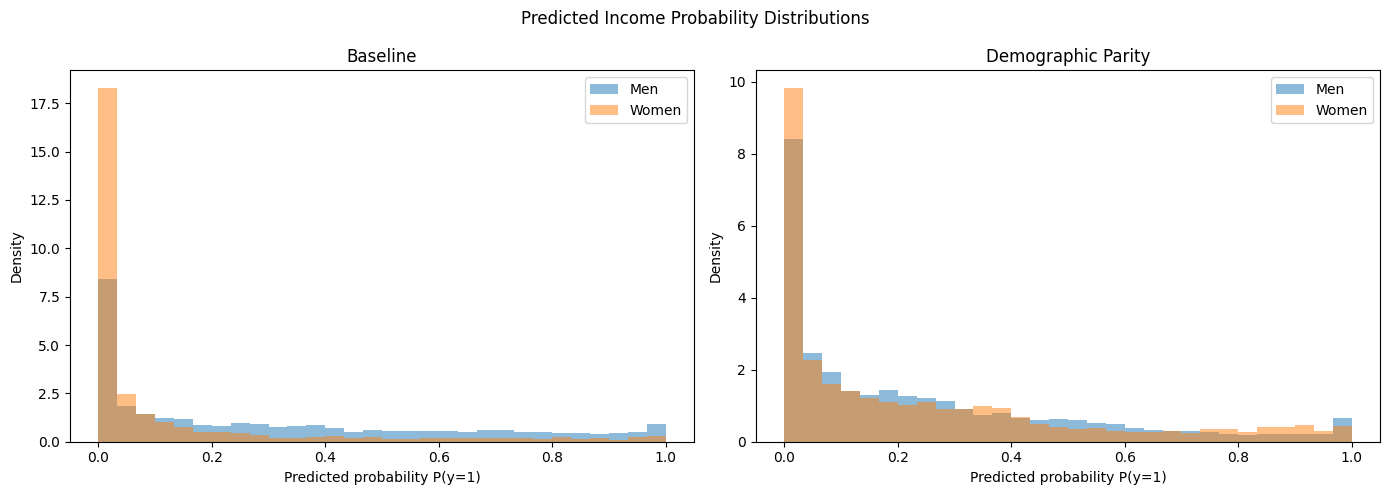

Saved scores.png successfully!


In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Get predictions
P_base.eval()
P_dp.eval()

with torch.no_grad():
    scores_base = torch.sigmoid(
        P_base(data["X_test"])
    ).squeeze().cpu().numpy()

    scores_dp = torch.sigmoid(
        P_dp(data["X_test"])
    ).squeeze().cpu().numpy()

z = data["z_test"].numpy()

# Create two overlapping histograms per model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, scores, title in [
    (axes[0], scores_base, "Baseline"),
    (axes[1], scores_dp, "Demographic Parity")
]:
    ax.hist(scores[z == 1], bins=30, alpha=0.5,
            label="Men", density=True)

    ax.hist(scores[z == 0], bins=30, alpha=0.5,
            label="Women", density=True)

    ax.set_title(title)
    ax.set_xlabel("Predicted probability P(y=1)")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Predicted Income Probability Distributions")
plt.tight_layout()
plt.savefig("scores.png", dpi=150)
plt.show()

print("Saved scores.png successfully!")

In [19]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

# Load the original Adult dataset
adult = fetch_openml("adult", version=2, as_frame=True)
df = adult.frame.dropna().reset_index(drop=True)

# Encode sex: Male = 1, Female = 0
z = (df["sex"].astype(str).str.strip() == "Male").astype(float)

# Remove target, sensitive attribute and fnlwgt
X_df = df.drop(columns=["class", "sex", "fnlwgt"])

# One-hot encode categorical features
X_encoded = pd.get_dummies(
    X_df,
    dtype=float
)

# Calculate correlation with sex
correlations = X_encoded.corrwith(z)

# Sort by absolute correlation
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print("TOP 20 FEATURES CORRELATED WITH SEX")
print(correlations.head(20).round(4))

TOP 20 FEATURES CORRELATED WITH SEX
relationship_Husband                 0.5816
marital-status_Married-civ-spouse    0.4381
relationship_Unmarried              -0.3218
relationship_Wife                   -0.3171
occupation_Adm-clerical             -0.2779
marital-status_Divorced             -0.2371
hours-per-week                       0.2314
occupation_Craft-repair              0.2281
marital-status_Never-married        -0.1787
marital-status_Widowed              -0.1773
relationship_Not-in-family          -0.1735
occupation_Other-service            -0.1654
occupation_Transport-moving          0.1344
race_Black                          -0.1152
marital-status_Separated            -0.1069
workclass_Self-emp-not-inc           0.1050
relationship_Own-child              -0.1036
race_White                           0.1033
occupation_Farming-fishing           0.1024
occupation_Priv-house-serv          -0.0942
dtype: float64


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


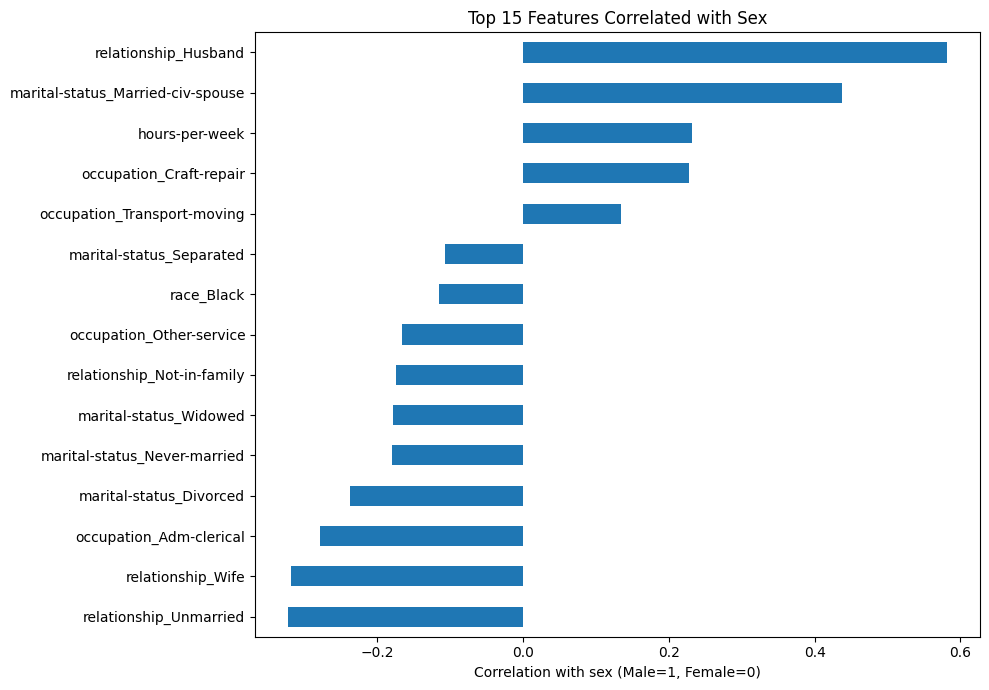

In [20]:
import matplotlib.pyplot as plt

top_features = correlations.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_features.plot(kind="barh")

plt.xlabel("Correlation with sex (Male=1, Female=0)")
plt.title("Top 15 Features Correlated with Sex")
plt.tight_layout()

plt.savefig("sex_correlations.png", dpi=150)
plt.show()

In [22]:
import torch
import torch.nn as nn
import train as train_module

class HiddenAdversary(nn.Module):
    def __init__(self, mode="eq_odds", hidden=32):
        super().__init__()

        assert mode in ("parity", "eq_odds")
        self.mode = mode
        self.c = nn.Parameter(torch.ones(1))

        n_in = 4 if mode == "eq_odds" else 1

        self.net = nn.Sequential(
            nn.Linear(n_in, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward(self, y_logit, y_true):
        s = torch.sigmoid((1 + self.c.abs()) * y_logit)

        if self.mode == "eq_odds":
            feats = torch.stack(
                [s, s * y_true, s * (1 - y_true), y_true],
                dim=-1
            )
        else:
            feats = s.unsqueeze(-1)

        return self.net(feats).squeeze(-1)

print("Hidden-layer adversary created successfully!")

Hidden-layer adversary created successfully!


In [23]:
import os

os.chdir("/kaggle/working/Debiasing")

original_adversary = train_module.Adversary

train_module.Adversary = HiddenAdversary

print("Q6 - Run 1: Hidden adversary with demographic parity")

P_hidden_dp, hist_hidden_dp = train_module.train(
    data,
    mode="parity",
    alpha=1.0,
    epochs=20,
    seed=42
)

Q6 - Run 1: Hidden adversary with demographic parity
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.4199 | L_A 0.6294 | acc 0.8201 | DP 0.032 | TPR 0.389 | FPR 0.054
epoch   5 | L_P 0.3610 | L_A 0.6302 | acc 0.8291 | DP 0.004 | TPR 0.311 | FPR 0.047
epoch  10 | L_P 0.3501 | L_A 0.6300 | acc 0.8353 | DP 0.010 | TPR 0.307 | FPR 0.037
epoch  15 | L_P 0.3459 | L_A 0.6303 | acc 0.8294 | DP 0.007 | TPR 0.345 | FPR 0.047
epoch  20 | L_P 0.3445 | L_A 0.6303 | acc 0.8331 | DP 0.012 | TPR 0.300 | FPR 0.037


In [24]:
print("Q6 - Run 2: Hidden adversary with equalized odds")

P_hidden_eo, hist_hidden_eo = train_module.train(
    data,
    mode="eq_odds",
    alpha=1.0,
    epochs=20,
    seed=42
)

# Restore original adversary class
train_module.Adversary = original_adversary

print("\nBoth Q6 experiments completed!")

Q6 - Run 2: Hidden adversary with equalized odds
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.3966 | L_A 0.6033 | acc 0.8399 | DP 0.118 | TPR 0.102 | FPR 0.037
epoch   5 | L_P 0.3235 | L_A 0.6005 | acc 0.8447 | DP 0.125 | TPR 0.092 | FPR 0.040
epoch  10 | L_P 0.3132 | L_A 0.5996 | acc 0.8457 | DP 0.135 | TPR 0.069 | FPR 0.046
epoch  15 | L_P 0.3074 | L_A 0.5998 | acc 0.8480 | DP 0.137 | TPR 0.047 | FPR 0.048
epoch  20 | L_P 0.3049 | L_A 0.5996 | acc 0.8478 | DP 0.128 | TPR 0.067 | FPR 0.044

Both Q6 experiments completed!


In [26]:
from train import train

print("Recovering original Equalized Odds history...")

P_eo_original, hist_eo = train(
    data,
    mode="eq_odds",
    alpha=1.0,
    epochs=20,
    seed=42
)

print("Original Equalized Odds history recovered!")

Recovering original Equalized Odds history...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.4224 | L_A 0.6363 | acc 0.8395 | DP 0.065 | TPR 0.176 | FPR 0.001
epoch   5 | L_P 0.3221 | L_A 0.5991 | acc 0.8464 | DP 0.093 | TPR 0.129 | FPR 0.019
epoch  10 | L_P 0.3126 | L_A 0.5986 | acc 0.8475 | DP 0.112 | TPR 0.111 | FPR 0.032
epoch  15 | L_P 0.3070 | L_A 0.5994 | acc 0.8451 | DP 0.111 | TPR 0.117 | FPR 0.030
epoch  20 | L_P 0.3050 | L_A 0.5998 | acc 0.8469 | DP 0.113 | TPR 0.110 | FPR 0.033
Original Equalized Odds history recovered!


In [28]:
import pandas as pd

q6_results = pd.DataFrame({
    "Original Parity": hist_dp.iloc[-1],
    "Hidden Parity": hist_hidden_dp.iloc[-1],
    "Original EO": hist_eo.iloc[-1],
    "Hidden EO": hist_hidden_eo.iloc[-1]
}).T

print(q6_results[
    ["accuracy", "DP gap", "TPR gap", "FPR gap"]
].round(4))

                 accuracy  DP gap  TPR gap  FPR gap
Original Parity    0.8269  0.0012   0.3100   0.0458
Hidden Parity      0.8331  0.0121   0.2998   0.0372
Original EO        0.8469  0.1130   0.1099   0.0330
Hidden EO          0.8478  0.1279   0.0675   0.0437


In [31]:
from pathlib import Path

train_file = Path("/kaggle/working/Debiasing/train.py")

# Read the original training file
code = train_file.read_text()

# Make sure the expected original lines exist
old_loop = "for epoch in range(1, epochs + 1):"
old_update = "w.grad = gp - proj - alpha * ga"

assert code.count(old_loop) == 1, "Could not uniquely find the epoch loop."
assert code.count(old_update) == 1, "Could not uniquely find the adversary update."

# Add the square-root schedule
code = code.replace(
    old_loop,
    old_loop + "\n        alpha_t = alpha * (epoch ** 0.5)"
)

# Use the changing weight in the predictor update
code = code.replace(
    old_update,
    "w.grad = gp - proj - alpha_t * ga"
)

# Save the modified file
train_file.write_text(code)

# Verify syntax
import py_compile
py_compile.compile(str(train_file), doraise=True)

print("Q7 modification successfully applied!")
print("Adversary weight: alpha_t = alpha * sqrt(epoch)")

Q7 modification successfully applied!
Adversary weight: alpha_t = alpha * sqrt(epoch)


In [32]:
import importlib
import train as train_module
import pandas as pd

# Load the updated train.py
importlib.reload(train_module)

print("Running Q7: Square-root adversary weight schedule...")

P_q7, hist_q7 = train_module.train(
    data,
    mode="eq_odds",
    alpha=1.0,
    debias=True,
    epochs=20,
    seed=42
)

print("\nQ7 training completed!")

Running Q7: Square-root adversary weight schedule...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.4224 | L_A 0.6363 | acc 0.8395 | DP 0.065 | TPR 0.176 | FPR 0.001
epoch   5 | L_P 0.3294 | L_A 0.6018 | acc 0.8429 | DP 0.070 | TPR 0.169 | FPR 0.002
epoch  10 | L_P 0.3257 | L_A 0.6033 | acc 0.8303 | DP 0.037 | TPR 0.234 | FPR 0.032
epoch  15 | L_P 0.3180 | L_A 0.6031 | acc 0.8387 | DP 0.065 | TPR 0.191 | FPR 0.008
epoch  20 | L_P 0.3146 | L_A 0.6030 | acc 0.8439 | DP 0.101 | TPR 0.128 | FPR 0.024

Q7 training completed!


In [33]:
q7_comparison = pd.DataFrame({
    "Original Baseline": hist_base.iloc[-1],
    "Q7 Square-root Schedule": hist_q7.iloc[-1]
}).T

print(q7_comparison[
    ["accuracy", "DP gap", "TPR gap", "FPR gap"]
].round(4))

                         accuracy  DP gap  TPR gap  FPR gap
Original Baseline          0.8492  0.1802   0.0835   0.0782
Q7 Square-root Schedule    0.8439  0.1013   0.1275   0.0243


In [35]:
from pathlib import Path
import py_compile

data_file = Path("/kaggle/working/Debiasing/data.py")
backup_file = Path("/kaggle/working/Debiasing/data_sex_backup.py")

code = data_file.read_text()

# Preserve original sex-based version (only create backup once)
if not backup_file.exists():
    backup_file.write_text(code)
    print("Original sex-based data.py backed up.")

# Check that the expected original code exists
assert 'z = (df["sex"].astype(str).str.strip() == "Male").astype(np.float32).values' in code
assert 'X_df = df.drop(columns=["class", "sex", "fnlwgt"])' in code

# Change sensitive attribute from sex to race
code = code.replace(
    'z = (df["sex"].astype(str).str.strip() == "Male").astype(np.float32).values',
    'z = (df["race"].astype(str).str.strip() == "White").astype(np.float32).values'
)

# Remove race from features, but keep sex
code = code.replace(
    'X_df = df.drop(columns=["class", "sex", "fnlwgt"])',
    'X_df = df.drop(columns=["class", "race", "fnlwgt"])'
)

# Update printed descriptions
code = code.replace(
    'P(z=Male)',
    'P(z=White)'
).replace(
    'P(y=1 | Male)',
    'P(y=1 | White)'
).replace(
    'P(y=1 | Female)',
    'P(y=1 | Non-White)'
)

data_file.write_text(code)

# Check syntax
py_compile.compile(str(data_file), doraise=True)

print("\nQ8 data.py modification successful!")
print("Sensitive attribute: White = 1, Non-White = 0")
print("Race removed from features.")
print("Sex retained as a feature.")

Original sex-based data.py backed up.

Q8 data.py modification successful!
Sensitive attribute: White = 1, Non-White = 0
Race removed from features.
Sex retained as a feature.


In [36]:
import importlib
import data as data_module

importlib.reload(data_module)

data_race = data_module.load_adult(verbose=True)

print("\nNumber of predictor features:", data_race["n_features"])

Train: (31655, 99), Test: (13567, 99)
P(y=1) = 0.248   P(z=White) = 0.860
P(y=1 | White) = 0.262   P(y=1 | Non-White) = 0.158

Number of predictor features: 99


In [37]:
from pathlib import Path
import py_compile

train_file = Path("/kaggle/working/Debiasing/train.py")
code = train_file.read_text()

old = "w.grad = gp - proj - alpha_t * ga"
new = "w.grad = gp - proj - alpha * ga"

assert code.count(old) == 1, "Expected Q7 update was not found exactly once."

code = code.replace(old, new)
train_file.write_text(code)

py_compile.compile(str(train_file), doraise=True)

print("Q8 training setup restored to original constant alpha.")
print("Multi-GPU setup remains unchanged.")

Q8 training setup restored to original constant alpha.
Multi-GPU setup remains unchanged.


In [38]:
import os

os.chdir("/kaggle/working/Debiasing")
!python main.py

Train: (31655, 99), Test: (13567, 99)
P(y=1) = 0.248   P(z=White) = 0.860
P(y=1 | White) = 0.262   P(y=1 | Non-White) = 0.158
Using device: cuda

=== 1. Baseline (no debiasing) ===
Predictor using GPUs: [0, 1]
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return F.linear(input, self.weight, self.bias)
epoch   1 | L_P 0.3669 | L_A 0.0000 | acc 0.8471 | DP 0.083 | TPR 0.038 | FPR 0.026
epoch   5 | L_P 0.3086 | L_A 0.0000 | acc 0.8474 | DP 0.088 | TPR 0.029 | FPR 0.032
epoch  10 | L_P 0.2996 | L_A 0.0000 | acc 0.8472 | DP 0.091 | TPR 0.035 | FPR 0.034
epoch  15 | L_P 0.2935 | L_A 0.0000 | acc 0.8507 | DP 0.082 | TPR 0.031 | FPR 0.026
epoch  20 | L_P 0.2913 | L_A 0.0000 | acc 0.8496 | DP 0.086 | TPR 0.032 | FPR 0.029

=== 2. Debiased: demographic parity ===
Predictor

In [40]:
from pathlib import Path
import py_compile

folder = Path("/kaggle/working/Debiasing")
models_file = folder / "models.py"
train_file = folder / "train.py"

# Back up both files before editing
for file in [models_file, train_file]:
    backup = file.with_name(file.stem + "_q9_backup.py")
    if not backup.exists():
        backup.write_text(file.read_text())
        print("Backup created:", backup.name)

# ---------- Modify models.py ----------
models_code = models_file.read_text()

old_assert = 'assert mode in ("parity", "eq_odds")'
new_assert = 'assert mode in ("parity", "eq_odds", "eq_opp")'

assert models_code.count(old_assert) == 1
models_code = models_code.replace(old_assert, new_assert)

# eq_opp uses the same single prediction feature as parity
old_input = 'n_in = 4 if mode == "eq_odds" else 1'
assert models_code.count(old_input) == 1

models_file.write_text(models_code)

# ---------- Modify train.py ----------
train_code = train_file.read_text()

old_predictor_block = """            if debias:
                z_logit = A(y_logit, yb)
                loss_a = F.binary_cross_entropy_with_logits(z_logit, zb)
                grad_p = torch.autograd.grad(loss_p, p_params, retain_graph=True)
                grad_a = torch.autograd.grad(loss_a, p_params, retain_graph=True)
                for w, gp, ga in zip(p_params, grad_p, grad_a):
                    unit_ga = ga / (ga.norm() + 1e-8)
                    proj = (gp * unit_ga).sum() * unit_ga   # part of gp that helps the adversary
                    w.grad = gp - proj - alpha * ga         # the paper's update rule
            else:
                loss_p.backward()
                loss_a = torch.tensor(0.0)"""

new_predictor_block = """            if debias:
                if mode == "eq_opp":
                    mask = (yb == 1)
                    if mask.any():
                        z_logit = A(y_logit[mask], yb[mask])
                        loss_a = F.binary_cross_entropy_with_logits(z_logit, zb[mask])
                    else:
                        loss_a = None
                else:
                    mask = None
                    z_logit = A(y_logit, yb)
                    loss_a = F.binary_cross_entropy_with_logits(z_logit, zb)

                if loss_a is not None:
                    grad_p = torch.autograd.grad(loss_p, p_params, retain_graph=True)
                    grad_a = torch.autograd.grad(loss_a, p_params, retain_graph=True)
                    for w, gp, ga in zip(p_params, grad_p, grad_a):
                        unit_ga = ga / (ga.norm() + 1e-8)
                        proj = (gp * unit_ga).sum() * unit_ga
                        w.grad = gp - proj - alpha * ga
                else:
                    loss_p.backward()
                    loss_a = loss_p.detach() * 0.0
            else:
                loss_p.backward()
                loss_a = torch.tensor(0.0)"""

assert train_code.count(old_predictor_block) == 1, \
    "Could not uniquely find the original predictor update block."

train_code = train_code.replace(old_predictor_block, new_predictor_block)

old_adversary_block = """            if debias:
                opt_a.zero_grad()
                z_logit = A(y_logit.detach(), yb)
                F.binary_cross_entropy_with_logits(z_logit, zb).backward()
                opt_a.step()"""

new_adversary_block = """            if debias:
                opt_a.zero_grad()
                if mode == "eq_opp":
                    mask = (yb == 1)
                    if mask.any():
                        z_logit = A(y_logit.detach()[mask], yb[mask])
                        F.binary_cross_entropy_with_logits(z_logit, zb[mask]).backward()
                        opt_a.step()
                else:
                    z_logit = A(y_logit.detach(), yb)
                    F.binary_cross_entropy_with_logits(z_logit, zb).backward()
                    opt_a.step()"""

assert train_code.count(old_adversary_block) == 1, \
    "Could not uniquely find the original adversary update block."

train_code = train_code.replace(old_adversary_block, new_adversary_block)

train_file.write_text(train_code)

# Compile both edited files
py_compile.compile(str(models_file), doraise=True)
py_compile.compile(str(train_file), doraise=True)

print("\nQ9 modifications successfully applied!")
print("New mode: eq_opp")
print("Adversary loss uses only examples where y = 1.")
print("Existing parity and eq_odds modes are preserved.")
print("Multi-GPU predictor setup is preserved.")

Backup created: models_q9_backup.py
Backup created: train_q9_backup.py

Q9 modifications successfully applied!
New mode: eq_opp
Adversary loss uses only examples where y = 1.
Existing parity and eq_odds modes are preserved.
Multi-GPU predictor setup is preserved.


In [41]:
import importlib
import models
import train as train_module

importlib.reload(models)
importlib.reload(train_module)

print("Q9: Training Equal Opportunity model on race...")

P_opp, hist_opp = train_module.train(
    data_race,
    mode="eq_opp",
    alpha=1.0,
    debias=True,
    epochs=20,
    seed=42
)

print("\nEqual Opportunity experiment completed!")

Q9: Training Equal Opportunity model on race...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.5832 | L_A 0.5026 | acc 0.7906 | DP 0.023 | TPR 0.107 | FPR 0.028
epoch   5 | L_P 0.3117 | L_A 0.3040 | acc 0.8477 | DP 0.052 | TPR 0.040 | FPR 0.007
epoch  10 | L_P 0.3004 | L_A 0.2980 | acc 0.8484 | DP 0.084 | TPR 0.009 | FPR 0.031
epoch  15 | L_P 0.2932 | L_A 0.3006 | acc 0.8481 | DP 0.086 | TPR 0.018 | FPR 0.031
epoch  20 | L_P 0.2905 | L_A 0.3006 | acc 0.8510 | DP 0.078 | TPR 0.015 | FPR 0.023

Equal Opportunity experiment completed!


In [42]:
q9_comparison = pd.DataFrame({
    "Equalized Odds": {
        "accuracy": 0.8487,
        "TPR gap": 0.0057,
        "FPR gap": 0.0253
    },
    "Equal Opportunity": hist_opp.iloc[-1][
        ["accuracy", "TPR gap", "FPR gap"]
    ]
}).T

print(q9_comparison.round(4))

                   accuracy  TPR gap  FPR gap
Equalized Odds       0.8487   0.0057   0.0253
Equal Opportunity    0.8510   0.0146   0.0227


In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from torch.utils.data import DataLoader

from models import Predictor, Adversary
from data import set_seed, SEED
from metrics import evaluate


# 1. Gradient Reversal Layer
class GradientReversal(torch.autograd.Function):

    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.alpha * grad_output, None


# 2. Separate GRL training function
def train_grl(data, alpha=1.0, epochs=20, batch_size=128,
              lr_p=1e-3, lr_a=1e-2, seed=SEED):

    set_seed(seed)
    device = data["device"]

    P = Predictor(data["n_features"]).to(device)

    # Preserve two-GPU predictor setup
    if torch.cuda.is_available() and torch.cuda.device_count() > 1:
        gpu_ids = list(range(torch.cuda.device_count()))
        P = torch.nn.DataParallel(P, device_ids=gpu_ids)
        print(f"Predictor using GPUs: {gpu_ids}")

    A = Adversary("eq_odds").to(device)

    opt_p = torch.optim.Adam(P.parameters(), lr=lr_p)
    opt_a = torch.optim.Adam(A.parameters(), lr=lr_a)

    sched_p = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_p, T_max=epochs
    )

    loader = DataLoader(
        data["train_ds"], batch_size=batch_size, shuffle=True
    )

    history = []

    for epoch in range(1, epochs + 1):
        P.train()
        A.train()

        total_lp = 0.0
        total_la = 0.0

        for xb, yb, zb in loader:
            xb, yb, zb = xb.to(device), yb.to(device), zb.to(device)

            opt_p.zero_grad()
            opt_a.zero_grad()

            # Predictor forward pass
            y_logit = P(xb)
            loss_p = F.binary_cross_entropy_with_logits(y_logit, yb)

            # Apply gradient reversal before the adversary
            reversed_logit = GradientReversal.apply(y_logit, alpha)

            # Adversary forward pass and loss
            z_logit = A(reversed_logit, yb)
            loss_a = F.binary_cross_entropy_with_logits(z_logit, zb)

            # One combined loss and ONE backward pass
            total_loss = loss_p + loss_a
            total_loss.backward()

            opt_p.step()
            opt_a.step()

            total_lp += loss_p.item() * len(xb)
            total_la += loss_a.item() * len(xb)

        sched_p.step()

        n = len(data["train_ds"])
        metrics = evaluate(
            P, data["X_test"], data["y_test"], data["z_test"]
        )

        history.append({
            "epoch": epoch,
            "loss_P": total_lp / n,
            "loss_A": total_la / n,
            **metrics
        })

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"epoch {epoch:3d} | "
                f"L_P {total_lp/n:.4f} | "
                f"L_A {total_la/n:.4f} | "
                f"acc {metrics['accuracy']:.4f} | "
                f"DP {metrics['DP gap']:.3f} | "
                f"TPR {metrics['TPR gap']:.3f} | "
                f"FPR {metrics['FPR gap']:.3f}"
            )

    return P, pd.DataFrame(history)


print("Gradient Reversal implementation ready!")

Gradient Reversal implementation ready!


In [45]:
print("Q10: Training with Gradient Reversal...")

P_grl, hist_grl = train_grl(
    data_race,
    alpha=1.0,
    epochs=20,
    seed=42
)

print("\nQ10 Gradient Reversal experiment completed!")

Q10: Training with Gradient Reversal...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.3678 | L_A 0.4234 | acc 0.8470 | DP 0.071 | TPR 0.019 | FPR 0.016
epoch   5 | L_P 0.3094 | L_A 0.3986 | acc 0.8475 | DP 0.067 | TPR 0.012 | FPR 0.015
epoch  10 | L_P 0.3012 | L_A 0.3988 | acc 0.8456 | DP 0.073 | TPR 0.003 | FPR 0.019
epoch  15 | L_P 0.2952 | L_A 0.3986 | acc 0.8491 | DP 0.067 | TPR 0.000 | FPR 0.014
epoch  20 | L_P 0.2931 | L_A 0.3988 | acc 0.8490 | DP 0.069 | TPR 0.014 | FPR 0.019

Q10 Gradient Reversal experiment completed!


In [46]:
q10_comparison = pd.DataFrame({
    "Race Baseline": {
        "accuracy": 0.8496,
        "DP gap": 0.0859,
        "TPR gap": 0.0321,
        "FPR gap": 0.0293
    },
    "Gradient Reversal": hist_grl.iloc[-1][
        ["accuracy", "DP gap", "TPR gap", "FPR gap"]
    ]
}).T

print(q10_comparison.round(4))

                   accuracy  DP gap  TPR gap  FPR gap
Race Baseline        0.8496  0.0859   0.0321   0.0293
Gradient Reversal    0.8490  0.0694   0.0138   0.0192


In [48]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from torch.utils.data import DataLoader

from data import set_seed, SEED
from metrics import evaluate


# Predictor that also returns its last hidden layer
class PredictorHidden(nn.Module):
    def __init__(self, n_in, hidden=64):
        super().__init__()
        self.fc1 = nn.Linear(n_in, hidden)
        self.fc2 = nn.Linear(hidden, hidden)
        self.fc3 = nn.Linear(hidden, 1)

    def forward(self, x):
        h1 = torch.relu(self.fc1(x))
        h2 = torch.relu(self.fc2(h1))  # 64-dimensional representation
        logits = self.fc3(h2).squeeze(-1)
        return logits, h2


# Adversary receives 64 hidden-layer values
class HiddenLayerAdversary(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.lin = nn.Linear(hidden, 1)

    def forward(self, hidden):
        return self.lin(hidden).squeeze(-1)


# Adapter for the existing evaluation function
class LogitOnly(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        logits, _ = self.model(x)
        return logits


# Q11 training function
def train_hidden_adversary(data, alpha=1.0, epochs=20,
                           batch_size=128, lr_p=1e-3,
                           lr_a=1e-2, seed=SEED):

    set_seed(seed)
    device = data["device"]

    P = PredictorHidden(data["n_features"]).to(device)

    # Keep the two-GPU setup
    if torch.cuda.is_available() and torch.cuda.device_count() > 1:
        gpu_ids = list(range(torch.cuda.device_count()))
        P = torch.nn.DataParallel(P, device_ids=gpu_ids)
        print(f"Predictor using GPUs: {gpu_ids}")

    A = HiddenLayerAdversary(hidden=64).to(device)

    opt_p = torch.optim.Adam(P.parameters(), lr=lr_p)
    opt_a = torch.optim.Adam(A.parameters(), lr=lr_a)

    sched_p = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_p, T_max=epochs
    )

    loader = DataLoader(
        data["train_ds"], batch_size=batch_size, shuffle=True
    )

    p_params = list(P.parameters())
    history = []

    for epoch in range(1, epochs + 1):
        P.train()
        A.train()

        total_lp = 0.0
        total_la = 0.0

        for xb, yb, zb in loader:
            xb, yb, zb = xb.to(device), yb.to(device), zb.to(device)

            # Forward pass
            logits, hidden = P(xb)
            loss_p = F.binary_cross_entropy_with_logits(logits, yb)

            # Adversary predicts race from the 64 hidden values
            z_logit = A(hidden)
            loss_a = F.binary_cross_entropy_with_logits(z_logit, zb)

            # Predictor update using gradient projection
            opt_p.zero_grad()

            grad_p = torch.autograd.grad(
                loss_p, p_params, retain_graph=True
            )
            grad_a = torch.autograd.grad(
                loss_a, p_params, retain_graph=True
            )

            for w, gp, ga in zip(p_params, grad_p, grad_a):
                unit_ga = ga / (ga.norm() + 1e-8)
                proj = (gp * unit_ga).sum() * unit_ga
                w.grad = gp - proj - alpha * ga

            opt_p.step()

            # Adversary update using detached hidden representation
            opt_a.zero_grad()
            z_logit_detached = A(hidden.detach())
            loss_a_detached = F.binary_cross_entropy_with_logits(
                z_logit_detached, zb
            )
            loss_a_detached.backward()
            opt_a.step()

            total_lp += loss_p.item() * len(xb)
            total_la += loss_a.item() * len(xb)

        sched_p.step()

        n = len(data["train_ds"])
        metrics = evaluate(
            LogitOnly(P),
            data["X_test"],
            data["y_test"],
            data["z_test"]
        )

        history.append({
            "epoch": epoch,
            "loss_P": total_lp / n,
            "loss_A": total_la / n,
            **metrics
        })

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"epoch {epoch:3d} | "
                f"L_P {total_lp/n:.4f} | "
                f"L_A {total_la/n:.4f} | "
                f"acc {metrics['accuracy']:.4f} | "
                f"DP {metrics['DP gap']:.3f} | "
                f"TPR {metrics['TPR gap']:.3f} | "
                f"FPR {metrics['FPR gap']:.3f}"
            )

    return P, pd.DataFrame(history)


print("Q11 hidden-layer adversary is ready!")

Q11 hidden-layer adversary is ready!


In [49]:
print("Q11: Training adversary on the last hidden layer...")

P_hidden64, hist_hidden64 = train_hidden_adversary(
    data_race,
    alpha=1.0,
    epochs=20,
    seed=42
)

print("\nQ11 experiment completed!")

Q11: Training adversary on the last hidden layer...
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.5516 | L_A 0.4875 | acc 0.8022 | DP 0.011 | TPR 0.064 | FPR 0.001
epoch   5 | L_P 0.3134 | L_A 0.4046 | acc 0.8483 | DP 0.066 | TPR 0.003 | FPR 0.015
epoch  10 | L_P 0.3079 | L_A 0.4109 | acc 0.8482 | DP 0.080 | TPR 0.019 | FPR 0.024
epoch  15 | L_P 0.3041 | L_A 0.4086 | acc 0.8493 | DP 0.078 | TPR 0.018 | FPR 0.022
epoch  20 | L_P 0.3026 | L_A 0.4007 | acc 0.8497 | DP 0.077 | TPR 0.018 | FPR 0.022

Q11 experiment completed!


In [50]:
q11_comparison = pd.DataFrame({
    "Original Parity (Q8)": {
        "accuracy": 0.8466,
        "DP gap": 0.0468
    },
    "64-D Hidden Adversary": hist_hidden64.iloc[-1][
        ["accuracy", "DP gap"]
    ]
}).T

print(q11_comparison.round(4))

                       accuracy  DP gap
Original Parity (Q8)     0.8466  0.0468
64-D Hidden Adversary    0.8497  0.0773


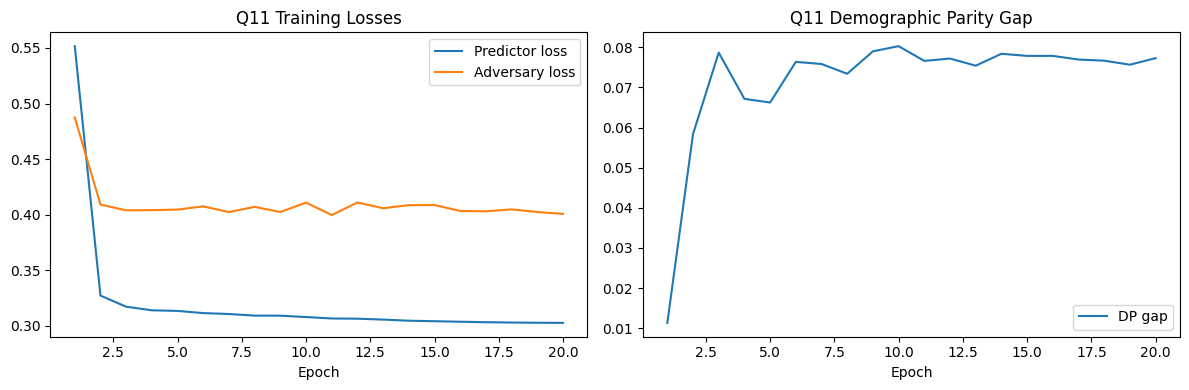

In [51]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    hist_hidden64["epoch"],
    hist_hidden64["loss_P"],
    label="Predictor loss"
)
axes[0].plot(
    hist_hidden64["epoch"],
    hist_hidden64["loss_A"],
    label="Adversary loss"
)
axes[0].set_title("Q11 Training Losses")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    hist_hidden64["epoch"],
    hist_hidden64["DP gap"],
    label="DP gap"
)
axes[1].set_title("Q11 Demographic Parity Gap")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [52]:
from pathlib import Path
import py_compile

folder = Path("/kaggle/working/Debiasing")

backup_file = folder / "data_sex_backup.py"
data_file = folder / "data.py"

assert backup_file.exists(), "Original sex-based backup not found."

data_file.write_text(backup_file.read_text())
py_compile.compile(str(data_file), doraise=True)

print("Original sex-based data.py restored successfully!")

Original sex-based data.py restored successfully!


In [53]:
import importlib
import data as data_module

importlib.reload(data_module)

data_sex = data_module.load_adult(verbose=True)

Train: (31655, 102), Test: (13567, 102)
P(y=1) = 0.248   P(z=Male) = 0.675
P(y=1 | Male) = 0.312   P(y=1 | Female) = 0.114


In [54]:
import numpy as np
import torch
import pandas as pd
import importlib
from sklearn.model_selection import train_test_split
import train as train_module

importlib.reload(train_module)

# Extract original training tensors
X_all, y_all, z_all = data_sex["train_ds"].tensors

# Stratify by both income label and sex
strata = (y_all.numpy().astype(int) * 2 +
          z_all.numpy().astype(int))

train_idx, val_idx = train_test_split(
    np.arange(len(y_all)),
    test_size=0.20,
    random_state=42,
    stratify=strata
)

# Training subset and validation tensors
train_subset = torch.utils.data.Subset(
    data_sex["train_ds"], train_idx.tolist()
)

X_val = X_all[val_idx].to(data_sex["device"])
y_val = y_all[val_idx]
z_val = z_all[val_idx]

# Same training/validation split for both models
data_q12 = {
    "train_ds": train_subset,
    "X_test": X_val,
    "y_test": y_val,
    "z_test": z_val,
    "n_features": data_sex["n_features"],
    "device": data_sex["device"]
}

print("Training examples:", len(train_idx))
print("Validation examples:", len(val_idx))

# Run 1: Baseline
print("\nQ12 Run 1: Baseline")
P_base_q12, hist_base_q12 = train_module.train(
    data_q12,
    debias=False,
    epochs=20,
    seed=42
)

# Run 2: Adversarial demographic parity
print("\nQ12 Run 2: Adversarial Parity")
P_parity_q12, hist_parity_q12 = train_module.train(
    data_q12,
    mode="parity",
    alpha=1.0,
    debias=True,
    epochs=20,
    seed=42
)

print("\nBoth Q12 training runs completed!")

Training examples: 25324
Validation examples: 6331

Q12 Run 1: Baseline
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.3931 | L_A 0.0000 | acc 0.8563 | DP 0.172 | TPR 0.013 | FPR 0.070
epoch   5 | L_P 0.3110 | L_A 0.0000 | acc 0.8626 | DP 0.166 | TPR 0.004 | FPR 0.062
epoch  10 | L_P 0.3013 | L_A 0.0000 | acc 0.8608 | DP 0.188 | TPR 0.028 | FPR 0.078
epoch  15 | L_P 0.2953 | L_A 0.0000 | acc 0.8615 | DP 0.183 | TPR 0.031 | FPR 0.075
epoch  20 | L_P 0.2926 | L_A 0.0000 | acc 0.8612 | DP 0.183 | TPR 0.035 | FPR 0.075

Q12 Run 2: Adversarial Parity
Predictor using GPUs: [0, 1]
epoch   1 | L_P 0.4143 | L_A 0.6352 | acc 0.8147 | DP 0.042 | TPR 0.452 | FPR 0.061
epoch   5 | L_P 0.3666 | L_A 0.6299 | acc 0.8281 | DP 0.006 | TPR 0.320 | FPR 0.066
epoch  10 | L_P 0.3545 | L_A 0.6297 | acc 0.8288 | DP 0.016 | TPR 0.394 | FPR 0.050
epoch  15 | L_P 0.3485 | L_A 0.6300 | acc 0.8379 | DP 0.014 | TPR 0.319 | FPR 0.044
epoch  20 | L_P 0.3472 | L_A 0.6302 | acc 0.8392 | DP 0.020 | TPR 0.302 | FPR 0.040

In [55]:
@torch.no_grad()
def get_probabilities(model, X):
    model.eval()
    return torch.sigmoid(model(X)).cpu().numpy()


# Baseline predictions on validation data
val_probs = get_probabilities(P_base_q12, X_val)
y_val_np = y_val.numpy()
z_val_np = z_val.numpy()

# Select a threshold that produces exactly k positive predictions
def threshold_for_count(probs, k):
    n = len(probs)

    if k == 0:
        return float(np.nextafter(probs.max(), np.inf))
    if k == n:
        return float(np.nextafter(probs.min(), -np.inf))

    sorted_probs = np.sort(probs)
    return float((sorted_probs[n-k-1] + sorted_probs[n-k]) / 2)


male_probs = val_probs[z_val_np == 1]
female_probs = val_probs[z_val_np == 0]

best = None

# Search common target positive rates
for target_rate in np.linspace(0, 1, 1001):
    km = round(target_rate * len(male_probs))
    kf = round(target_rate * len(female_probs))

    tm = threshold_for_count(male_probs, km)
    tf = threshold_for_count(female_probs, kf)

    val_pred = np.zeros(len(val_probs))
    val_pred[z_val_np == 1] = (
        male_probs >= tm
    ).astype(float)
    val_pred[z_val_np == 0] = (
        female_probs >= tf
    ).astype(float)

    male_rate = val_pred[z_val_np == 1].mean()
    female_rate = val_pred[z_val_np == 0].mean()
    dp_gap = abs(male_rate - female_rate)
    accuracy = (val_pred == y_val_np).mean()

    if best is None or (
        dp_gap <= 0.002 and
        (best["DP gap"] > 0.002 or accuracy > best["accuracy"])
    ):
        best = {
            "male_threshold": tm,
            "female_threshold": tf,
            "DP gap": dp_gap,
            "accuracy": accuracy
        }

male_threshold = best["male_threshold"]
female_threshold = best["female_threshold"]

print("Selected male threshold:", round(male_threshold, 4))
print("Selected female threshold:", round(female_threshold, 4))
print("Validation accuracy:", round(best["accuracy"], 4))
print("Validation DP gap:", round(best["DP gap"], 4))

Selected male threshold: 0.6925
Selected female threshold: 0.2028
Validation accuracy: 0.836
Validation DP gap: 0.0001


In [56]:
import numpy as np
import pandas as pd
import torch

@torch.no_grad()
def predict_probs(model, X):
    model.eval()
    return torch.sigmoid(model(X)).detach().cpu().numpy()


def fairness_results(y_true, z_true, y_pred):
    male = (z_true == 1)
    female = (z_true == 0)

    male_positive = y_pred[male].mean()
    female_positive = y_pred[female].mean()

    male_tpr = y_pred[male & (y_true == 1)].mean()
    female_tpr = y_pred[female & (y_true == 1)].mean()

    male_fpr = y_pred[male & (y_true == 0)].mean()
    female_fpr = y_pred[female & (y_true == 0)].mean()

    return {
        "accuracy": (y_pred == y_true).mean(),
        "DP gap": abs(male_positive - female_positive),
        "TPR gap": abs(male_tpr - female_tpr),
        "FPR gap": abs(male_fpr - female_fpr)
    }


# Original untouched test set
X_test = data_sex["X_test"]
y_test = data_sex["y_test"].numpy()
z_test = data_sex["z_test"].numpy()

# Baseline predictions with separate male/female thresholds
base_probs_test = predict_probs(P_base_q12, X_test)

base_group_preds = np.where(
    z_test == 1,
    base_probs_test >= male_threshold,
    base_probs_test >= female_threshold
).astype(float)

# Adversarial parity predictions with standard threshold 0.5
parity_probs_test = predict_probs(P_parity_q12, X_test)
parity_preds = (parity_probs_test >= 0.5).astype(float)

# Calculate test metrics
threshold_results = fairness_results(
    y_test, z_test, base_group_preds
)

parity_results = fairness_results(
    y_test, z_test, parity_preds
)

q12_test_comparison = pd.DataFrame({
    "Baseline + Separate Thresholds": threshold_results,
    "Adversarial Parity": parity_results
}).T

print("Q12 TEST SET COMPARISON")
print(q12_test_comparison.round(4))

print("\nSelected validation thresholds:")
print("Male:", round(male_threshold, 4))
print("Female:", round(female_threshold, 4))

Q12 TEST SET COMPARISON
                                accuracy  DP gap  TPR gap  FPR gap
Baseline + Separate Thresholds    0.8272  0.0154   0.3599   0.0548
Adversarial Parity                0.8276  0.0024   0.2884   0.0466

Selected validation thresholds:
Male: 0.6925
Female: 0.2028
